# Benchmarks: harv against The Joker

This notebook times the rejection step of `harv` and of The Joker (v1.3.1) on the same
simulated RV data with the same prior, and makes the scaling figure and numbers for the
performance appendix of the paper. The Joker runs on one CPU core. `harv` runs on one
CPU core and, when JAX sees one, on one GPU.

Run this on the benchmark workstation (see `scripts/README.md`). On Linux, the first cell
pins the process to one CPU core; on macOS, JAX spreads the work of `harv` over several
cores, so the CPU numbers there are not for one core. For the GPU line, install
CUDA-enabled jaxlib with `uv sync --group cuda`. Most of the run time is The Joker at
large $N$, where its cost per prior sample grows faster than linearly with $N$; the
$N = 128$ cell alone takes about 7 minutes on the workstation.

The results are saved to `data/benchmarks-thejoker.ecsv`. If that file exists, the
notebook skips the timings and only makes the summary and the figure, so delete the
file to rerun them.

In [1]:
import os

# One CPU core for both codes. This has to happen before numpy, jax or pymc are
# imported, because each starts its thread pools on import.
os.environ["XLA_FLAGS"] = (
    "--xla_cpu_multi_thread_eigen=false intra_op_parallelism_threads=1"
)
for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[var] = "1"
if hasattr(os, "sched_setaffinity"):  # Linux only
    os.sched_setaffinity(0, {min(os.sched_getaffinity(0))})

import jax

# Enable float64 before importing harv:
jax.config.update("jax_enable_x64", True)

In [2]:
import time
import warnings
from pathlib import Path

import astropy.table as at
import astropy.units as u
import harv
import harv.models as hm
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist
import pymc as pm
import thejoker as tj
from harv.simulate import simulate_rv_sb1_data
from scipy.special import logsumexp
from unxt import Q

%matplotlib inline
print(f"harv {harv.__version__}, thejoker {tj.__version__}, jax {jax.__version__}")
print(jax.devices())

# With the simulated data below only one or a few prior samples survive, by design, so
# harv's warning that the run is under-resolved is expected here.
warnings.filterwarnings("ignore", message="Under-resolved rejection run")

harv 0.0.2.dev238+g4d7e5d20a, thejoker 1.3.1, jax 0.11.2
[CpuDevice(id=0)]


In [3]:
repo_path = Path("..").resolve()
figure_path = repo_path / "paper" / "figures"
data_path = repo_path / "data"
figure_path.mkdir(exist_ok=True)
data_path.mkdir(exist_ok=True)

In [4]:
results_path = data_path / "benchmarks-thejoker.ecsv"
run_benchmarks = not results_path.exists()

## The prior

We use the prior from Case study 1 in both codes: log-uniform period between 2 and
16,384 days, a truncated normal eccentricity, uniform angles, the period-dependent
prior on $K$ with $\sigma_{K,0} = 30~{\rm km\,s^{-1}}$ at $P_0 = 1~{\rm yr}$, and a
normal prior on $v_0$ with $\sigma_{v_0} = 150~{\rm km\,s^{-1}}$. The prior matters
for the timing: The Joker solves Kepler's equation iteratively, so eccentric draws
cost more.

In [5]:
prior = hm.StandardRV().default_prior(
    period_min=Q(2.0, "day"),
    period_max=Q(16384.0, "day"),
    sigma_K0=Q(30.0, "km/s"),
    sigma_v0=Q(150.0, "km/s"),
    eccentricity=dist.TruncatedNormal(0.5, 0.25, low=0.0, high=1.0),
)
model = harv.RVModel()
sampler = harv.RejectionSampler(prior, model)

with pm.Model():
    e = tj.units.with_unit(
        pm.TruncatedNormal("e", 0.5, 0.25, lower=0.0, upper=1.0), u.one
    )
    tj_prior = tj.JokerPrior.default(
        P_min=2 * u.day,
        P_max=16384 * u.day,
        sigma_K0=30 * u.km / u.s,
        P0=1 * u.year,
        sigma_v=150 * u.km / u.s,
        pars={"e": e},
    )
joker = tj.TheJoker(tj_prior, rng=np.random.default_rng(0))


def to_thejoker(data):
    """The same data as a thejoker RVData, with times in days."""
    return tj.RVData(
        t=np.asarray(data.time.to_value("day")),
        rv=np.asarray(data.rv.to_value("km/s")) * u.km / u.s,
        rv_err=np.asarray(data.rv_err.to_value("km/s")) * u.km / u.s,
    )

/Users/aprice-whelan/projects/harv-paper/.venv/lib/python3.14/site-packages/pymc_ext/optim.py:4: FutureWarning: `pytensor.graph.basic.graph_inputs` was moved to `pytensor.graph.traversal.graph_inputs`. Calling it from the old location will fail in a future release.
  from pytensor.graph.basic import graph_inputs


## Both codes compute the same marginal likelihood

Before timing anything, we check that the two codes compute the same thing. The
parameter conventions differ (The Joker uses the mean anomaly at a reference time,
`harv` the phase of pericenter), so instead of comparing sample by sample we compare
the evidence estimate $\ln Z = {\rm logsumexp}(\ln \mathcal{G}_j) - \ln J$ from
independent prior libraries. For this we use the 3-visit APOGEE source with small RV
scatter from Case study 1, where $J_{\rm eff} \gg 1$.

In [6]:
if run_benchmarks:
    tbl = at.Table.read(repo_path / "data" / "apogee" / "counts0_scatter1.ecsv")
    apogee_data = harv.RVData(
        time=Q(tbl["jd"], "day"),
        rv=Q(tbl["rv"], "km/s"),
        rv_err=Q(tbl["rv_err"], "km/s"),
    )
    J_check = 1_000_000

    s = sampler.run_with_samples(
        apogee_data,
        prior.sample(J_check, key=jax.random.key(0), model=model),
        key=jax.random.key(1),
        return_evidence_stats=True,
    )
    lnZ_harv = float(s.metadata["ln_Z_int"])
    err_harv = float(s.metadata["ln_Z_int_mcse"])

    # The Joker draws prior samples through `pymc.draw`, which calls a compiled function
    # once per sample, so this takes a minute or two. We reuse this library for the timings
    # below.
    t0 = time.perf_counter()
    tj_base = tj_prior.sample(J_check, rng=np.random.default_rng(1))
    t_tj_lib = time.perf_counter() - t0

    lnL = np.asarray(
        joker.marginal_ln_likelihood(to_thejoker(apogee_data), tj_base, in_memory=True)
    )
    w = np.exp(lnL - lnL.max())
    ess = w.sum() ** 2 / (w**2).sum()
    lnZ_tj = logsumexp(lnL) - np.log(J_check)
    err_tj = np.sqrt(1 / ess - 1 / J_check)

    diff = lnZ_harv - lnZ_tj
    print(f"{tbl.meta['APOGEE_ID']}:")
    print(f"  harv     ln Z = {lnZ_harv:.4f} +/- {err_harv:.4f}")
    print(f"  thejoker ln Z = {lnZ_tj:.4f} +/- {err_tj:.4f}")
    print(f"  difference = {diff:.4f} ({diff / np.hypot(err_harv, err_tj):.1f} sigma)")
    assert abs(diff) < 4 * np.hypot(err_harv, err_tj)

## Simulated data

For the timings we use simulated RV data with the same orbit as `harv`'s own benchmark
suite (Section D of the harv docs): $P = 200$ days, $e = 0.3$, $K = 10~{\rm km\,s^{-1}}$
and uncertainties of $0.5~{\rm km\,s^{-1}}$ over a 3-year baseline. The cost per prior
sample depends on the number of observations $N$, not on the data values. With these
data, only one or a few samples survive, so the timings measure the marginal
likelihood evaluations.

In [7]:
TRUTH = {
    "period": Q(200.0, "day"),
    "eccentricity": 0.3,
    "rv_semiamp": Q(10.0, "km/s"),
    "v_sys": Q(0.0, "km/s"),
    "rv_err": Q(0.5, "km/s"),
    "baseline": Q(3.0, "yr"),
}


def simulate(n_obs):
    data, _ = simulate_rv_sb1_data(seed=42, n_obs=n_obs, **TRUTH)
    return data

## Timing

We time the rejection step on a prior library that is already in memory, as it is
when one library is shared by all sources in a survey. For `harv`, we report the
median of three warm calls; the first call also includes JIT compilation. The Joker
has no compilation step, and the evidence check above has already run its code, so
for it we time one call. Generating the prior library is a separate, one-off cost
that we time below.

We use two grids: library size $J$ from $10^4$ to $10^7$ at $N = 8$ (typical for
APOGEE), and $N$ from 4 to 128 at $J = 10^6$.

In [8]:
J_VALUES = (10_000, 100_000, 1_000_000, 10_000_000)
N_VALUES = (4, 8, 16, 32, 64, 128)
J_FIXED, N_FIXED = 1_000_000, 8
grid = [(N_FIXED, J) for J in J_VALUES] + [(N, J_FIXED) for N in N_VALUES]
grid = sorted(set(grid))


def time_call(f, *args, repeats=3, **kwargs):
    """Time of the first call, and median time of the next `repeats` calls."""
    times = []
    for _ in range(repeats + 1):
        t0 = time.perf_counter()
        jax.block_until_ready(f(*args, **kwargs))
        times.append(time.perf_counter() - t0)
    return times[0], float(np.median(times[1:]))


devices = {"harv, 1 CPU core": jax.devices("cpu")[0]}
if jax.default_backend() == "gpu":
    devices["harv, 1 GPU"] = jax.devices()[0]
J_max = max(J_VALUES)

Generating the prior libraries (one-off costs). Drawing $10^7$ samples with The Joker
would take about 15 minutes, so its library repeats the $10^6$ samples from the
evidence check ten times. Its cost per sample does not depend on which samples it gets.

In [9]:
if run_benchmarks:
    t_lib = {"thejoker": (J_check, t_tj_lib)}
    tj_library = tj_base[np.tile(np.arange(J_check), J_max // J_check)]

    libraries = {}
    for name, device in devices.items():
        with jax.default_device(device):
            t0 = time.perf_counter()
            libraries[name] = jax.block_until_ready(
                prior.sample(J_max, key=jax.random.key(3), model=model)
            )
            t_lib[name] = (J_max, time.perf_counter() - t0)

    print("Prior library generation (first call, including compilation):")
    for name, (J, t) in t_lib.items():
        print(
            f"  {name}: {t:.2f} s for J = {J:.0e}, {1e6 * t / J:.3g} s per 10^6 samples"
        )

In [10]:
if run_benchmarks:
    rows = []
    for n_obs, J in grid:
        data = simulate(n_obs)
        n_before = len(rows)
        # The Joker has no compilation step, so one call is enough.
        t0 = time.perf_counter()
        joker.rejection_sample(to_thejoker(data), tj_library[:J], in_memory=True)
        t = time.perf_counter() - t0
        rows.append({"code": "thejoker", "N": n_obs, "J": J, "first": t, "warm": t})

        # harv pads the library to a whole number of batches, so for small libraries the
        # batch is the whole library (as in harv's own benchmarks).
        sampler_J = harv.RejectionSampler(prior, model, batch_size=min(100_000, J))
        for name, device in devices.items():
            with jax.default_device(device):
                first, warm = time_call(
                    sampler_J.run_with_samples,
                    data,
                    libraries[name][:J],
                    key=jax.random.key(4),
                )
            rows.append(
                {"code": name, "N": n_obs, "J": J, "first": first, "warm": warm}
            )

        print(", ".join(f"{r['code']} {r['warm']:.3g} s" for r in rows[n_before:]))

    results = at.Table(rows)
    results["throughput"] = results["J"] / results["warm"]  # prior samples per second
    results["compile"] = results["first"] - results["warm"]
    results.write(results_path)
else:
    results = at.Table.read(results_path)

## Results

In [11]:
codes = list(dict.fromkeys(results["code"]))
for J in J_VALUES:
    sub = results[(results["N"] == N_FIXED) & (results["J"] == J)]
    tj_time = sub["warm"][sub["code"] == "thejoker"][0]
    print(
        f"N = {N_FIXED}, J = {J:.0e}: "
        + ", ".join(
            f"{r['code']} {r['warm']:.3g} s ({tj_time / r['warm']:.0f}x)" for r in sub
        )
    )

print()
for n_obs in N_VALUES:
    sub = results[(results["N"] == n_obs) & (results["J"] == J_FIXED)]
    print(
        f"N = {n_obs:3d}, J = {J_FIXED:.0e}: "
        + ", ".join(f"{r['code']} {r['throughput'] / 1e6:.3g} M/s" for r in sub)
    )

print("\nharv compile time per data shape:")
for name in codes:
    if name != "thejoker":
        sub = results[results["code"] == name]
        print(f"  {name}: {sub['compile'].min():.1f} to {sub['compile'].max():.1f} s")

N = 8, J = 1e+04: thejoker 0.0472 s (1x), harv, 1 CPU core 0.019 s (2x), harv, 1 GPU 0.0123 s (4x)
N = 8, J = 1e+05: thejoker 0.422 s (1x), harv, 1 CPU core 0.174 s (2x), harv, 1 GPU 0.0141 s (30x)
N = 8, J = 1e+06: thejoker 4.23 s (1x), harv, 1 CPU core 1.54 s (3x), harv, 1 GPU 0.0259 s (163x)
N = 8, J = 1e+07: thejoker 42.4 s (1x), harv, 1 CPU core 15.4 s (3x), harv, 1 GPU 0.139 s (305x)

N =   4, J = 1e+06: thejoker 0.516 M/s, harv, 1 CPU core 0.834 M/s, harv, 1 GPU 40.6 M/s
N =   8, J = 1e+06: thejoker 0.237 M/s, harv, 1 CPU core 0.649 M/s, harv, 1 GPU 38.7 M/s
N =  16, J = 1e+06: thejoker 0.0869 M/s, harv, 1 CPU core 0.485 M/s, harv, 1 GPU 32.9 M/s
N =  32, J = 1e+06: thejoker 0.0288 M/s, harv, 1 CPU core 0.31 M/s, harv, 1 GPU 26.7 M/s
N =  64, J = 1e+06: thejoker 0.00847 M/s, harv, 1 CPU core 0.178 M/s, harv, 1 GPU 18.3 M/s
N = 128, J = 1e+06: thejoker 0.00227 M/s, harv, 1 CPU core 0.0962 M/s, harv, 1 GPU 12.1 M/s

harv compile time per data shape:
  harv, 1 CPU core: 1.1 to 3.6 

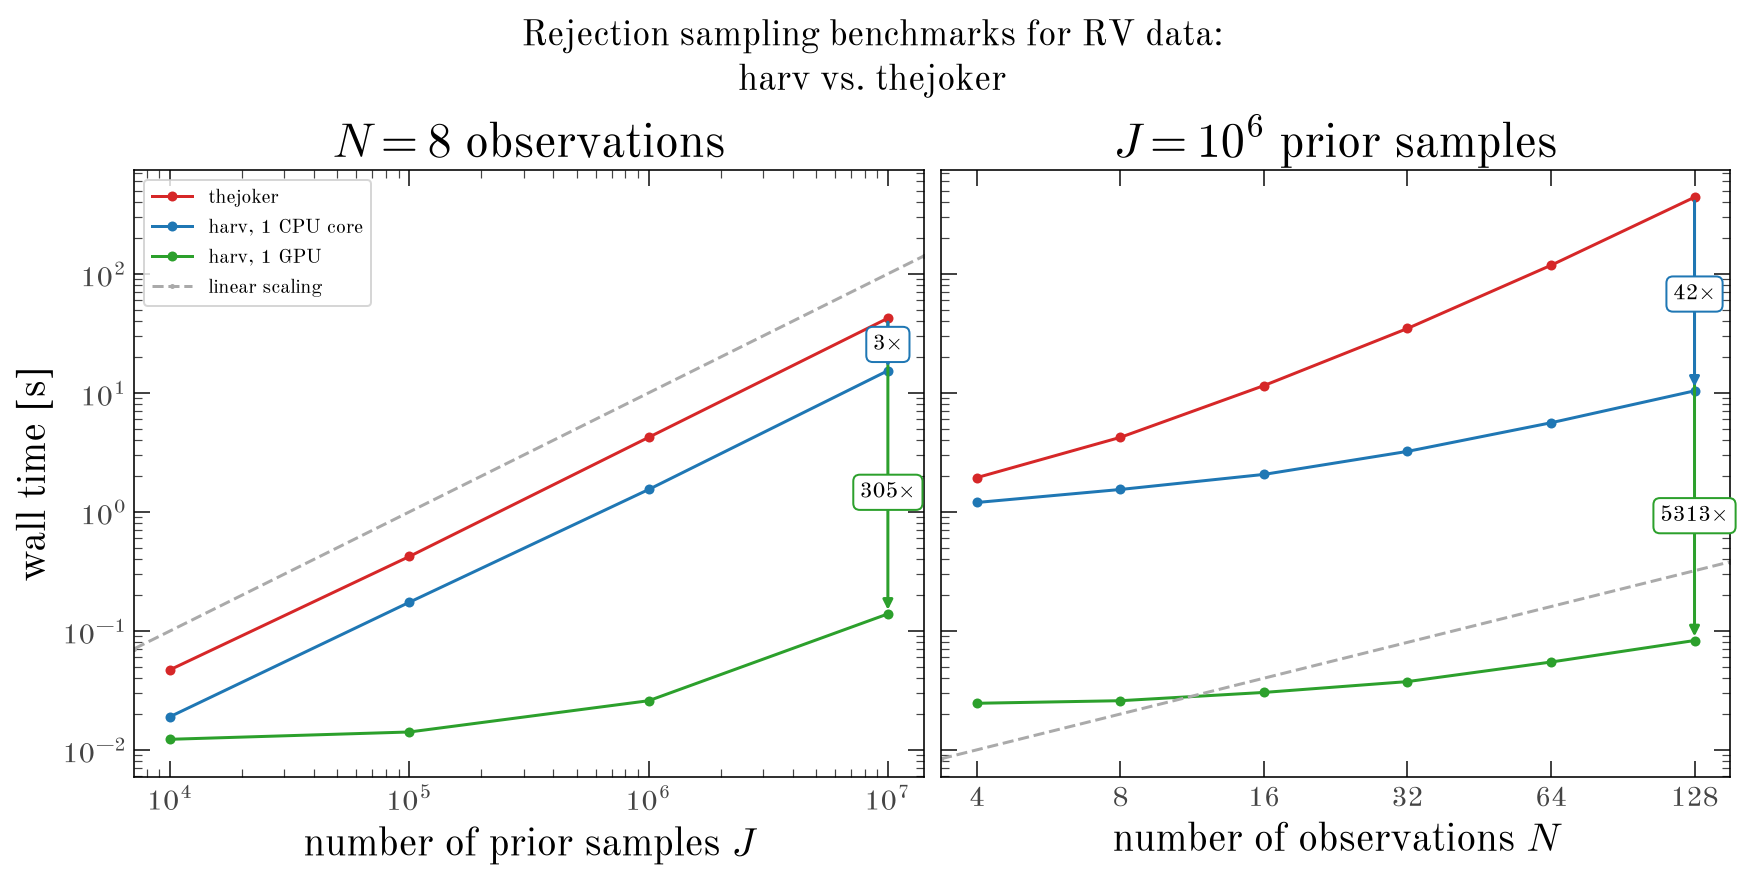

In [12]:
colors = {
    "thejoker": "tab:red",
    "harv, 1 CPU core": "tab:blue",
    "harv, 1 GPU": "tab:green",
}
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True, layout="constrained")

for code in codes:
    sub = results[(results["code"] == code) & (results["N"] == N_FIXED)]
    sub = sub[np.argsort(sub["J"])]
    sub = sub[np.isin(sub["J"], J_VALUES)]
    axes[0].plot(sub["J"], sub["warm"], marker="o", color=colors[code], label=code)

    sub = results[(results["code"] == code) & (results["J"] == J_FIXED)]
    sub = sub[np.argsort(sub["N"])]
    axes[1].plot(sub["N"], sub["warm"], marker="o", color=colors[code], label=code)

axes[0].axline(
    (1e4, 1e-1), slope=1.0, color="#aaaaaa", linestyle="--", label="linear scaling"
)
axes[1].axline(
    (4, 1e-2), slope=1.0, color="#aaaaaa", linestyle="--", label="linear scaling"
)


def speedup_arrows(ax, sel, x):
    """Arrows at x from The Joker's time down to each harv time, labeled with the speed-up.

    `sel` selects one cell of the grid. The arrows share one vertical line, so each label
    sits on the part of the line between the previous arrow tip and its own tip.
    """
    t_tj = results["warm"][sel & (results["code"] == "thejoker")][0]
    harv = [
        (code, results["warm"][sel & (results["code"] == code)][0]) for code in codes
    ]
    harv = sorted((c for c in harv if c[0] != "thejoker"), key=lambda c: -c[1])
    # Longest arrow first, so that the shorter ones are drawn on top of it:
    for code, t in harv[::-1]:
        arrow = {"arrowstyle": "-|>", "color": colors[code], "lw": 1.5}
        ax.annotate("", xy=(x, t), xytext=(x, t_tj), arrowprops=arrow)
    t_top = t_tj
    for code, t in harv:
        ax.text(
            x,
            np.sqrt(t * t_top),
            rf"{t_tj / t:.0f}$\times$",
            ha="center",
            va="center",
            fontsize=11,
            bbox={"boxstyle": "round,pad=0.3", "fc": "white", "ec": colors[code]},
        )
        t_top = t


J_arrow, N_arrow = max(J_VALUES), max(N_VALUES)
speedup_arrows(axes[0], (results["N"] == N_FIXED) & (results["J"] == J_arrow), J_arrow)
speedup_arrows(axes[1], (results["J"] == J_FIXED) & (results["N"] == N_arrow), N_arrow)

axes[0].set_xlabel("number of prior samples $J$")
axes[0].set_ylabel("wall time [s]")
axes[0].set_title(f"$N = {N_FIXED}$ observations")
axes[1].set_xlabel("number of observations $N$")
axes[1].set_title(f"$J = 10^{{{np.log10(J_FIXED):.0f}}}$ prior samples")
for ax in axes:
    ax.set_xscale("log")
    ax.set_yscale("log")
axes[1].set_xticks(N_VALUES, [str(n) for n in N_VALUES])
# Not minorticks_off(), which would also remove the minor ticks of the shared y-axis:
axes[1].xaxis.set_minor_locator(plt.NullLocator())
axes[0].legend(loc="upper left")

fig.suptitle(
    "Rejection sampling benchmarks for RV data:\nharv vs. thejoker", fontsize=18
)

fig.savefig(figure_path / "bench-thejoker.pdf")